# Taller: Combinando Modelos · Hard vs Soft Voting en Yomi Level
**Aprendizaje Supervisado · Universidad Sergio Arboleda**
José Santiago González · Oscar Mateo Arrubla · Leonardo Diasgranados · Docente: Hernán Cruz Bueno

**Sector:** aprendizaje de japonés con contenido audiovisual (anime, doramas y cine japonés).
**Pregunta:** ¿combinar los modelos que ya entrenamos en los talleres (KNN, SVM y Random Forest) predice mejor si el japonés de un título será *Fácil*, *Intermedio* o *Difícil* para un estudiante?

In [1]:
# ============================================================
# 📦 Librerías
# ============================================================
import os, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report, roc_auc_score)
warnings.filterwarnings('ignore')
os.makedirs('figuras', exist_ok=True)
plt.rcParams['figure.dpi'] = 110
ORDEN = ["Fácil", "Intermedio", "Difícil"]

## Fase 1 · Exploración del dataset

**Dataset:** Moe-DB + AniList + TMDB, con **9.977 títulos** japoneses (anime de TV, películas de anime, doramas y películas live-action). Tras quitar 943 títulos sin metadatos quedan **9.034**.

| Aspecto | Detalle |
|---|---|
| Variables de entrada | **28**: palabras por episodio, palabras únicas y episodios (en logaritmo), año de estreno, anime/live-action, película/serie, género desconocido y 21 géneros (multi-hot) |
| Variable objetivo | `Overall Difficulty` (1-100) cortada en terciles: **Fácil** (< 19,9), **Intermedio** (19,9-25,4) y **Difícil** (> 25,4) |
| Tipo de salida | Categórica, 3 clases → **clasificación multiclase** |
| Tamaño | 7.227 títulos de entrenamiento y 1.807 de prueba (80/20 estratificado, semilla 42) |
| Balance | **Balanceado**: 3.017 / 3.015 / 3.002. Adivinar al azar acierta 33% |

**¿Por qué clasificación y no regresión?** La decisión del negocio es por niveles: la app muestra un semáforo (verde, amarillo, rojo) y recomienda según el nivel del estudiante. Además, la dificultad exacta está muy concentrada entre 15 y 30 puntos (gráfica de abajo), así que predecir "23,4 frente a 24,1" no cambia ninguna decisión; lo útil es saber en qué grupo cae. Es la misma variable objetivo de todos nuestros talleres, lo que permite comparar el ensemble con los modelos que ya teníamos.

**Fuga de datos evitada:** no usamos la dificultad de kanji, la de vocabulario ni la densidad de vocabulario, porque `Overall Difficulty` se calcula con ellas.

In [2]:
# ============================================================
# 📂 Fase 1 · Cargar y preparar el dataset (mismo preprocesamiento del proyecto)
# ============================================================
# El CSV se lee junto al notebook; en Colab, si no se subió, se descarga del repositorio
ruta = ('moe_db_anilist_dataset.csv' if os.path.exists('moe_db_anilist_dataset.csv')
        else 'https://raw.githubusercontent.com/JoSker51/TallerC3_2/main/moe_db_anilist_dataset.csv')
df = pd.read_csv(ruta)
print("Filas originales:", len(df))

# Quitamos los títulos sin ningún metadato (no tienen formato ni géneros)
df = df[df['entry_type'].notna()].copy()

# Variable objetivo: dificultad (1-100) cortada en terciles -> 3 clases del mismo tamaño
df['nivel'], cortes = pd.qcut(df['Overall Difficulty (1-100)'], 3, labels=ORDEN, retbins=True)

# Episodios y año faltantes: mediana de su mismo formato (la global no sirve para películas y series a la vez)
for c in ['episodes', 'start_year']:
    df[c] = df[c].fillna(df.groupby('entry_type')[c].transform('median'))

# Formato -> dos binarias; géneros -> multi-hot (21 géneros con al menos 100 títulos)
df['genero_desconocido'] = df['genres'].isna().astype(int)
df['es_anime'] = df['entry_type'].str.startswith('anime').astype(int)
df['es_pelicula'] = df['entry_type'].str.endswith('movie').astype(int)
g = (df['genres'].fillna('')
     .str.replace('Sci-Fi & Fantasy', 'Sci-Fi, Fantasy', regex=False)
     .str.replace('Action & Adventure', 'Action, Adventure', regex=False)
     .str.replace('War & Politics', 'War', regex=False)
     .str.replace('Science Fiction', 'Sci-Fi', regex=False))
gen = g.str.get_dummies(sep=', ')
gen = gen.loc[:, gen.sum() >= 100]
gen.columns = ['g_' + c for c in gen.columns]
df = pd.concat([df, gen], axis=1)

# Logaritmo a las variables muy sesgadas
for c in ['Avg. Words/Episode', 'Unique Words', 'episodes']:
    df['log_' + c] = np.log1p(df[c])

# 28 variables. NO usamos Kanji/Vocab Difficulty ni Vocab Density: la etiqueta se calcula con ellas (fuga de datos)
NUM = ['log_Avg. Words/Episode', 'log_Unique Words', 'log_episodes', 'start_year']
FMT = ['es_anime', 'es_pelicula', 'genero_desconocido']
features = NUM + FMT + list(gen.columns)
X, y = df[features], df['nivel'].astype(str)

# Misma división de todos los talleres: 80/20 estratificada, semilla 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Títulos usados: {len(df)} | variables: {len(features)} | train: {len(X_train)} | test: {len(X_test)}")
print("Cortes de dificultad:", np.round(cortes, 1))
print("\nBalance de clases:"); print(y.value_counts().reindex(ORDEN).to_string())

Filas originales: 9977
Títulos usados: 9034 | variables: 28 | train: 7227 | test: 1807
Cortes de dificultad: [ 2.3 19.9 25.4 72.3]

Balance de clases:
nivel
Fácil         3017
Intermedio    3015
Difícil       3002


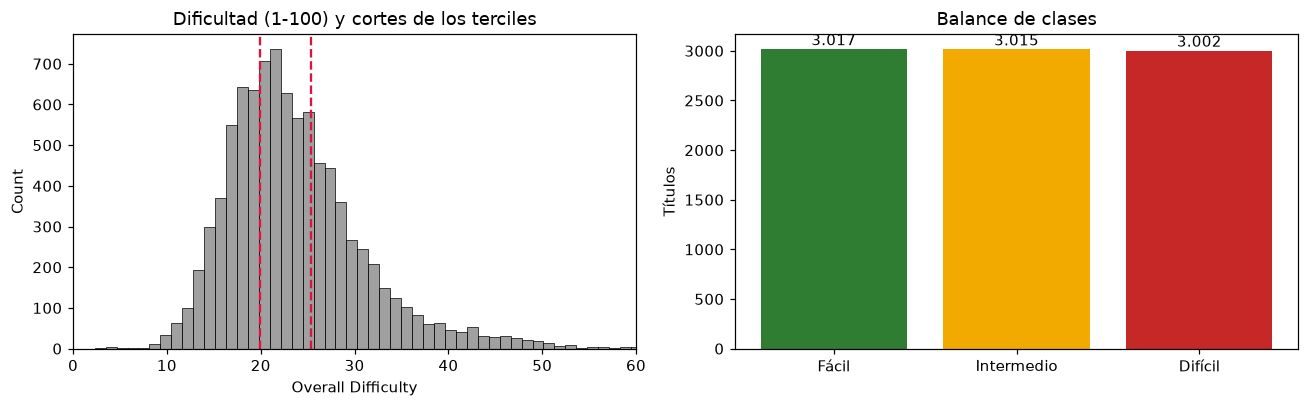

In [3]:
# 📊 Distribución de la dificultad y balance de clases
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(df['Overall Difficulty (1-100)'], bins=60, color='gray', ax=ax[0])
for c in cortes[1:3]:
    ax[0].axvline(c, color='crimson', linestyle='--')
ax[0].set_title('Dificultad (1-100) y cortes de los terciles'); ax[0].set_xlabel('Overall Difficulty')
ax[0].set_xlim(0, 60)
conteo = y.value_counts().reindex(ORDEN)
ax[1].bar(ORDEN, conteo.values, color=['#2E7D32', '#F2A900', '#C62828'])
for i, v in enumerate(conteo.values):
    ax[1].text(i, v + 40, f"{v:,}".replace(',', '.'), ha='center')
ax[1].set_title('Balance de clases'); ax[1].set_ylabel('Títulos')
plt.tight_layout(); plt.savefig('figuras/1_dataset.png'); plt.show()

## Fase 2 · Modelos base

Usamos los **3 modelos que trabajamos en los talleres**, cada uno con los parámetros que encontramos allí. Son de **familias distintas**, que es lo que pide el voting:

| Modelo | Familia | Parámetros (del taller) | Cómo decide |
|---|---|---|---|
| **KNN** | Basado en distancias | K=39, Manhattan, pesos por distancia (GridSearchCV, 5 folds) | Vota entre los 39 títulos más parecidos |
| **SVM** | Basado en márgenes | Kernel RBF, C=100, gamma='scale' (GridSearch de 20 combinaciones) | Traza la frontera con mayor margen entre clases |
| **Random Forest** | Ensamble de árboles | 300 árboles, profundidad 15, 40% de variables por división | 300 árboles con reglas "si… entonces" que votan |

Medimos **Accuracy**, **F1-macro**, el **recall de la clase Difícil** (la que más importa: recomendar algo difícil a un principiante provoca abandono) y los **errores graves** (confundir Fácil con Difícil o al revés).

In [4]:
# ============================================================
# 🤖 Fase 2 · Modelos base: los mismos parámetros que encontramos en cada taller
# ============================================================
# KNN y SVM necesitan escalado -> van dentro de un Pipeline con StandardScaler.
# Random Forest no lo necesita.
modelos_base = {
    # Taller KNN: GridSearchCV con 5 folds eligió K=39, distancia Manhattan y pesos por distancia
    'KNN': make_pipeline(StandardScaler(),
                         KNeighborsClassifier(n_neighbors=39, metric='manhattan', weights='distance')),
    # Taller SVM: GridSearch de 20 combinaciones eligió kernel RBF, C=100, gamma='scale'.
    # probability=True es obligatorio para poder usar Soft Voting.
    'SVM': make_pipeline(StandardScaler(),
                         SVC(kernel='rbf', C=100, gamma='scale', probability=True, random_state=42)),
    # Proyecto (modelo final): 300 árboles, profundidad 15, 40% de las variables por división
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=15, max_features=0.4,
                                            random_state=42, n_jobs=-1),
}

def errores_graves(real, pred):
    """% de títulos donde se confunde un extremo con el otro (Fácil <-> Difícil)."""
    real, pred = np.asarray(real), np.asarray(pred)
    return np.mean(((real == 'Fácil') & (pred == 'Difícil')) | ((real == 'Difícil') & (pred == 'Fácil')))

def metricas(real, pred):
    return {'Accuracy': accuracy_score(real, pred),
            'F1-macro': f1_score(real, pred, average='macro'),
            'Recall Difícil': recall_score(real, pred, labels=['Difícil'], average='macro'),
            'Errores graves': errores_graves(real, pred)}

pred, proba, tabla = {}, {}, {}
for nombre, modelo in modelos_base.items():
    modelo.fit(X_train, y_train)
    pred[nombre] = modelo.predict(X_test)
    proba[nombre] = modelo.predict_proba(X_test)
    tabla[nombre] = metricas(y_test, pred[nombre])

pd.DataFrame(tabla).T.round(3)

,Accuracy,F1-macro,Recall Difícil,Errores graves
KNN,0.546,0.544,0.602,0.079
SVM,0.570,0.568,0.662,0.065
Random Forest,0.581,0.580,0.650,0.061


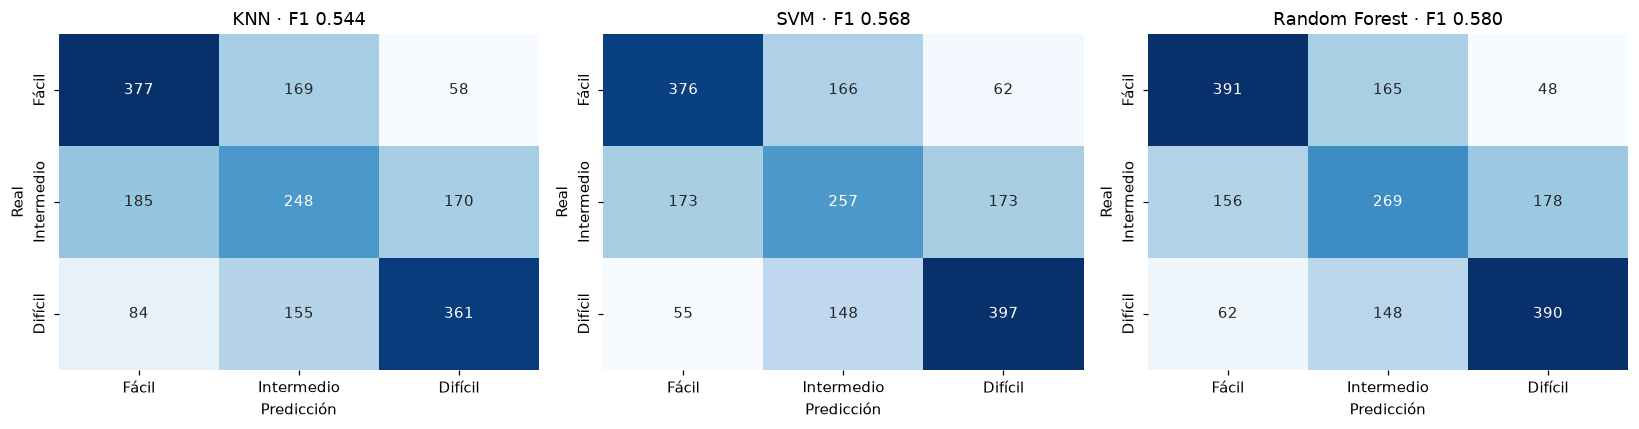

In [5]:
# 🔲 Matrices de confusión de los modelos base
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nombre in zip(axes, modelos_base):
    cm = confusion_matrix(y_test, pred[nombre], labels=ORDEN)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=ORDEN, yticklabels=ORDEN)
    ax.set_title(f"{nombre} · F1 {tabla[nombre]['F1-macro']:.3f}")
    ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
plt.tight_layout(); plt.savefig('figuras/2_cm_base.png'); plt.show()

## Fase 3 · Voting Ensemble

- **Hard Voting:** cada modelo vota por un nivel y gana la mayoría. Si los 3 dicen algo distinto, hay empate.
- **Soft Voting:** cada modelo da una probabilidad para cada nivel, se promedian y gana el nivel con mayor promedio. Por eso el SVM necesita `probability=True`.

In [6]:
# ============================================================
# 🗳️ Fase 3 · VotingClassifier: Hard y Soft con los 3 modelos base
# ============================================================
estimadores = list(modelos_base.items())

# Hard: cada modelo vota por una clase y gana la mayoría
voting_hard = VotingClassifier(estimators=estimadores, voting='hard', n_jobs=-1)
# Soft: se promedian las probabilidades de los 3 modelos y gana la clase con mayor promedio
voting_soft = VotingClassifier(estimators=estimadores, voting='soft', n_jobs=-1)

for nombre, modelo in [('Voting Hard', voting_hard), ('Voting Soft', voting_soft)]:
    modelo.fit(X_train, y_train)
    pred[nombre] = modelo.predict(X_test)
    tabla[nombre] = metricas(y_test, pred[nombre])
proba['Voting Soft'] = voting_soft.predict_proba(X_test)

resultados = pd.DataFrame(tabla).T
resultados.round(3)

,Accuracy,F1-macro,Recall Difícil,Errores graves
KNN,0.546,0.544,0.602,0.079
SVM,0.570,0.568,0.662,0.065
Random Forest,0.581,0.580,0.650,0.061
Voting Hard,0.583,0.580,0.673,0.068
Voting Soft,0.593,0.591,0.663,0.056


In [7]:
# 📋 Reporte por clase del mejor ensemble (Soft)
print(classification_report(y_test, pred['Voting Soft'], labels=ORDEN, digits=3))

              precision    recall  f1-score   support

       Fácil      0.639     0.672     0.655       604
  Intermedio      0.473     0.444     0.459       603
     Difícil      0.657     0.663     0.660       600

    accuracy                          0.593      1807
   macro avg      0.590     0.593     0.591      1807
weighted avg      0.590     0.593     0.591      1807



In [8]:
# 🔍 ¿Qué tanto coinciden los modelos entre sí? (la diversidad es lo que hace funcionar el voting)
votos = pd.DataFrame({k: pred[k] for k in modelos_base}, index=X_test.index)
print(f"Los 3 modelos dicen lo mismo en el {(votos.nunique(axis=1) == 1).mean():.1%} de los títulos")
print(f"Los 3 dicen algo distinto (empate) en el {(votos.nunique(axis=1) == 3).mean():.1%}")
for a, b in itertools.combinations(modelos_base, 2):
    print(f"  {a} y {b} coinciden en el {(votos[a] == votos[b]).mean():.1%}")
print("\n¿Con qué modelo base coincide más cada ensemble?")
for ens in ['Voting Hard', 'Voting Soft']:
    print(f"  {ens}: " + ", ".join(f"{k} {np.mean(pred[ens] == pred[k]):.1%}" for k in modelos_base))

Los 3 modelos dicen lo mismo en el 60.1% de los títulos
Los 3 dicen algo distinto (empate) en el 3.2%
  KNN y SVM coinciden en el 74.3%
  KNN y Random Forest coinciden en el 71.3%
  SVM y Random Forest coinciden en el 71.4%

¿Con qué modelo base coincide más cada ensemble?
  Voting Hard: KNN 86.4%, SVM 86.8%, Random Forest 83.8%
  Voting Soft: KNN 82.6%, SVM 85.0%, Random Forest 83.2%


In [9]:
# 🎬 La decisión del ensemble en casos reales: títulos donde los modelos no se ponen de acuerdo
clases = list(voting_soft.classes_)
info = df.loc[X_test.index, ['Anime Title', 'entry_type', 'start_year', 'Overall Difficulty (1-100)']]
filas = []
for i, idx in enumerate(X_test.index):
    if votos.loc[idx].nunique() > 1:
        fila = {'Título': info.loc[idx, 'Anime Title'], 'Real': y_test.loc[idx]}
        for k in modelos_base:
            p = proba[k][i][clases.index(pred[k][i])]
            fila[k] = f"{pred[k][i]} ({p:.0%})"
        fila['Hard'] = pred['Voting Hard'][i]
        fila['Soft'] = f"{pred['Voting Soft'][i]} ({proba['Voting Soft'][i].max():.0%})"
        filas.append(fila)
casos = pd.DataFrame(filas)
# Casos donde Hard y Soft deciden distinto: ahí se ve el efecto de la "confianza" de cada modelo
distintos = casos[casos['Hard'] != casos['Soft'].str.split(' ').str[0]]
print(f"Hard y Soft deciden distinto en {len(distintos)} títulos ({len(distintos)/len(X_test):.1%} del test)")
print(f"Soft acierta en {np.mean(distintos['Soft'].str.split(' ').str[0] == distintos['Real']):.0%} de esos casos; "
      f"Hard en {np.mean(distintos['Hard'] == distintos['Real']):.0%}")
distintos.head(8)

Hard y Soft deciden distinto en 149 títulos (8.2% del test)
Soft acierta en 44% de esos casos; Hard en 31%


,Título,Real,KNN,SVM,Random Forest,Hard,Soft
0,Ginban Kaleidoscope,Intermedio,Intermedio (50%),Difícil (41%),Fácil (43%),Difícil,Intermedio (39%)
10,ONE PIECE. Norowareta Seiken,Intermedio,Fácil (50%),Difícil (27%),Difícil (41%),Difícil,Fácil (38%)
12,LOVE STAGE!!,Difícil,Fácil (49%),Intermedio (52%),Fácil (48%),Fácil,Intermedio (46%)
19,Totsugawa Keibu Series,Difícil,Difícil (46%),Fácil (46%),Intermedio (54%),Difícil,Intermedio (43%)
20,GON 2nd Season,Fácil,Difícil (47%),Fácil (53%),Difícil (35%),Difícil,Fácil (36%)
26,Free!. Timeless Medley - Yakusoku,Fácil,Fácil (50%),Intermedio (58%),Fácil (51%),Fácil,Intermedio (44%)
29,Uramichi Oniisan,Intermedio,Fácil (46%),Fácil (50%),Intermedio (55%),Fácil,Intermedio (44%)
33,Acchi Kocchi. PLACE=PRINCESS,Fácil,Fácil (46%),Intermedio (53%),Fácil (57%),Fácil,Intermedio (44%)


## Fase 4 · Visualización

Primero comparamos las métricas y las matrices de confusión; después medimos qué pasa al **quitar o agregar modelos** del ensemble (ablación).

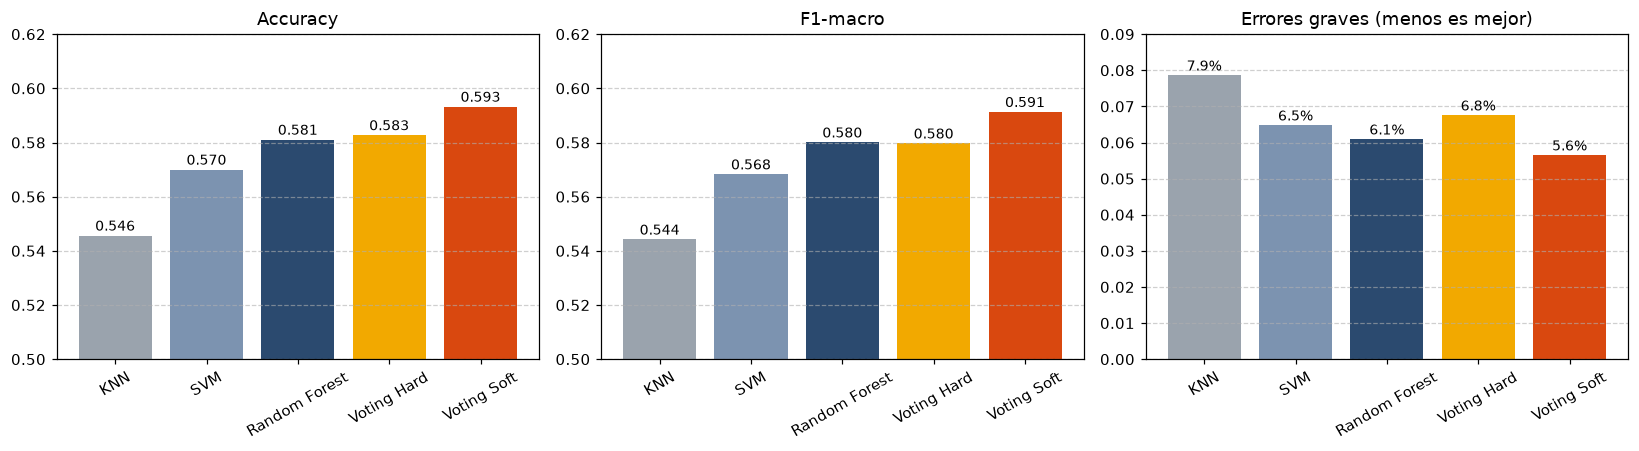

In [10]:
# ============================================================
# 📈 Fase 4 · Comparación de métricas entre modelos base y ensembles
# ============================================================
orden_m = ['KNN', 'SVM', 'Random Forest', 'Voting Hard', 'Voting Soft']
colores = ['#9AA3AD', '#7C93B0', '#2B4A6F', '#F2A900', '#D9480F']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, met, lim in zip(axes, ['Accuracy', 'F1-macro', 'Errores graves'], [(0.50, 0.62), (0.50, 0.62), (0, 0.09)]):
    v = resultados.loc[orden_m, met]
    barras = ax.bar(orden_m, v, color=colores)
    for b in barras:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + (lim[1] - lim[0]) * 0.015,
                f"{b.get_height():.1%}" if met == 'Errores graves' else f"{b.get_height():.3f}", ha='center', fontsize=9)
    ax.set_ylim(*lim); ax.set_title(met + (' (menos es mejor)' if met == 'Errores graves' else ''))
    ax.tick_params(axis='x', rotation=30); ax.grid(axis='y', linestyle='--', alpha=0.6)
axes[0].axhline(1/3, color='gray', linestyle=':')
plt.tight_layout(); plt.savefig('figuras/3_comparacion.png'); plt.show()

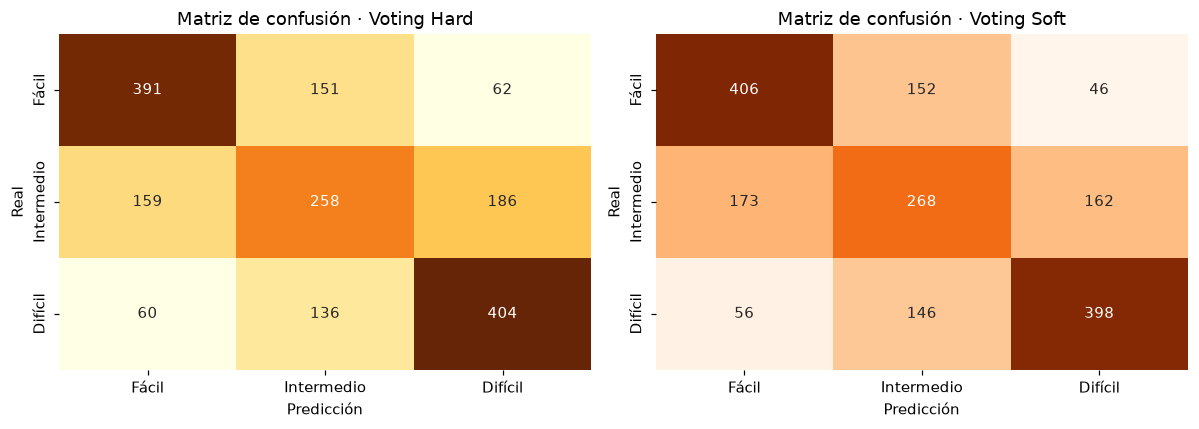

In [11]:
# 🔲 Matrices de confusión: Hard vs Soft
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nombre in zip(axes, ['Voting Hard', 'Voting Soft']):
    cm = confusion_matrix(y_test, pred[nombre], labels=ORDEN)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges' if 'Soft' in nombre else 'YlOrBr', cbar=False,
                ax=ax, xticklabels=ORDEN, yticklabels=ORDEN)
    ax.set_title(f"Matriz de confusión · {nombre}"); ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
plt.tight_layout(); plt.savefig('figuras/4_cm_voting.png'); plt.show()

In [12]:
# ➕➖ ¿Cómo cambia el desempeño al quitar o agregar modelos del ensemble?
# Combinaciones de 2 y 3 modelos, en Hard y en Soft
ablacion = []
for r in (1, 2, 3):
    for combo in itertools.combinations(modelos_base, r):
        for tipo in (['hard', 'soft'] if r > 1 else ['individual']):
            if r == 1:
                p = pred[combo[0]]
            else:
                vc = VotingClassifier([(k, modelos_base[k]) for k in combo], voting=tipo, n_jobs=-1).fit(X_train, y_train)
                p = vc.predict(X_test)
            ablacion.append({'Modelos': ' + '.join(combo), 'n': r, 'Voting': tipo,
                             'F1-macro': f1_score(y_test, p, average='macro'), 'Errores graves': errores_graves(y_test, p)})
ablacion = pd.DataFrame(ablacion)
ablacion.round(4)

,Modelos,n,Voting,F1-macro,Errores graves
0,KNN,1,individual,0.5442,0.0786
1,SVM,1,individual,0.5683,0.0647
2,Random Forest,1,individual,0.5800,0.0609
3,KNN + SVM,2,hard,0.5500,0.0885
4,KNN + SVM,2,soft,0.5814,0.0647
5,KNN + Random Forest,2,hard,0.5559,0.0819
6,KNN + Random Forest,2,soft,0.5718,0.0664
7,SVM + Random Forest,2,hard,0.5635,0.0858
8,SVM + Random Forest,2,soft,0.5843,0.0570
9,KNN + SVM + Random Forest,3,hard,0.5797,0.0675


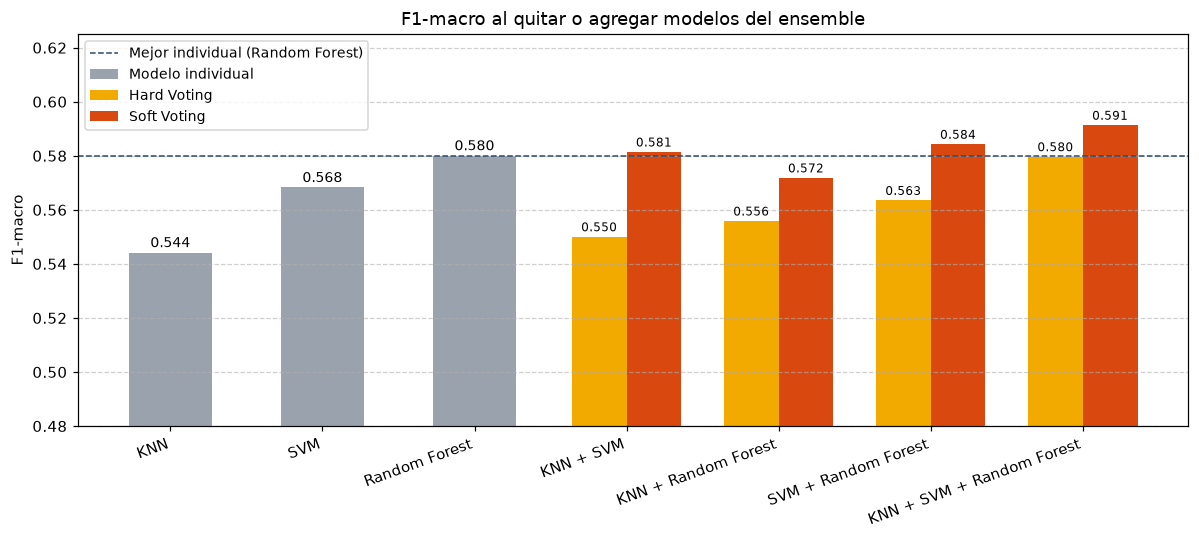

In [13]:
# 📊 Gráfica de la ablación
fig, ax = plt.subplots(figsize=(11, 5))
ind = ablacion[ablacion['n'] == 1].set_index('Modelos')['F1-macro']
comb = ablacion[ablacion['n'] > 1].pivot(index='Modelos', columns='Voting', values='F1-macro')
comb = comb.loc[['KNN + SVM', 'KNN + Random Forest', 'SVM + Random Forest', 'KNN + SVM + Random Forest']]
etiquetas = list(ind.index) + list(comb.index)
xs = np.arange(len(etiquetas))
ax.bar(xs[:3], ind.values, color='#9AA3AD', width=0.55, label='Modelo individual')
ax.bar(xs[3:] - 0.18, comb['hard'].values, width=0.36, color='#F2A900', label='Hard Voting')
ax.bar(xs[3:] + 0.18, comb['soft'].values, width=0.36, color='#D9480F', label='Soft Voting')
for x, v in zip(xs[:3], ind.values): ax.text(x, v + 0.002, f"{v:.3f}", ha='center', fontsize=9)
for x, h, s in zip(xs[3:], comb['hard'].values, comb['soft'].values):
    ax.text(x - 0.18, h + 0.002, f"{h:.3f}", ha='center', fontsize=8); ax.text(x + 0.18, s + 0.002, f"{s:.3f}", ha='center', fontsize=8)
ax.axhline(ind.max(), color='#2B4A6F', linestyle='--', linewidth=1, label='Mejor individual (Random Forest)')
ax.set_xticks(xs); ax.set_xticklabels(etiquetas, rotation=20, ha='right'); ax.set_ylim(0.48, 0.625)
ax.set_ylabel('F1-macro'); ax.set_title('F1-macro al quitar o agregar modelos del ensemble')
ax.legend(loc='upper left', fontsize=9); ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout(); plt.savefig('figuras/5_ablacion.png'); plt.show()

### Experimento extra: ¿y si el problema fuera desbalanceado?

Nuestras 3 clases están balanceadas por construcción. Para responder la pregunta de la Fase 5 sobre datos **desbalanceados**, repetimos el ejercicio con la pregunta del negocio en forma binaria: **"¿este título es Difícil, sí o no?"**. Ahí solo 1 de cada 3 títulos es positivo. En este caso un **falso negativo** es un título difícil que el sistema deja pasar como "no difícil" (llega a un principiante), y un **falso positivo** es un título que no era difícil pero se marca en rojo (se pierde una recomendación).

In [14]:
# ============================================================
# ⚖️ Experimento extra: problema desbalanceado "¿Es Difícil? (sí/no)" -> 1 de cada 3 es positivo
# ============================================================
ytr_b, yte_b = (y_train == 'Difícil').astype(int), (y_test == 'Difícil').astype(int)
print(f"Proporción de títulos difíciles en test: {yte_b.mean():.1%}")

from sklearn.base import clone
bin_modelos = {k: clone(m) for k, m in modelos_base.items()}
bin_res, bin_proba = {}, {}
for k, m in bin_modelos.items():
    m.fit(X_train, ytr_b); p = m.predict(X_test); bin_proba[k] = m.predict_proba(X_test)[:, 1]; bin_res[k] = p
for tipo in ['hard', 'soft']:
    vc = VotingClassifier(list(bin_modelos.items()), voting=tipo, n_jobs=-1).fit(X_train, ytr_b)
    bin_res[f'Voting {tipo.title()}'] = vc.predict(X_test)
    if tipo == 'soft':
        bin_proba['Voting Soft'] = vc.predict_proba(X_test)[:, 1]

def fila_bin(real, p, pr=None):
    tn, fp, fn, tp = confusion_matrix(real, p).ravel()
    return {'Accuracy': accuracy_score(real, p), 'F1 (Difícil)': f1_score(real, p),
            'Precisión': precision_score(real, p), 'Recall': recall_score(real, p),
            'Falsos positivos': fp, 'Falsos negativos': fn,
            'AUC': roc_auc_score(real, pr) if pr is not None else np.nan}

tabla_bin = pd.DataFrame({k: fila_bin(yte_b, p, bin_proba.get(k)) for k, p in bin_res.items()}).T
tabla_bin.round(3)

Proporción de títulos difíciles en test: 33.2%


,Accuracy,F1 (Difícil),Precisión,Recall,Falsos positivos,Falsos negativos,AUC
KNN,0.754,0.558,0.693,0.467,124.0,320.0,0.792
SVM,0.775,0.635,0.687,0.590,161.0,246.0,0.807
Random Forest,0.769,0.614,0.691,0.552,148.0,269.0,0.820
Voting Hard,0.780,0.617,0.730,0.535,119.0,279.0,NaN
Voting Soft,0.780,0.600,0.755,0.498,97.0,301.0,0.831


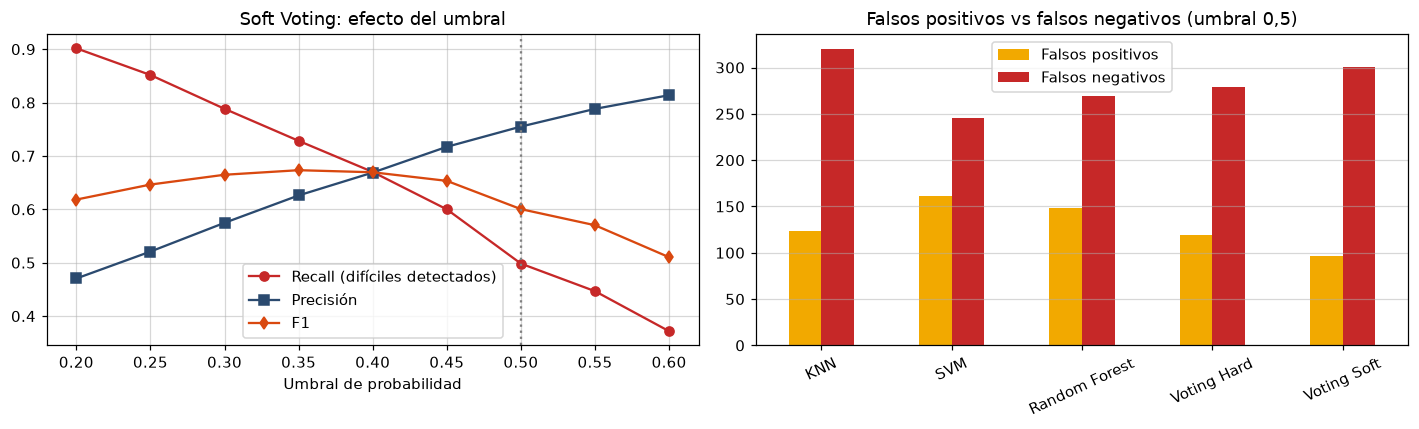

,Accuracy,F1 (Difícil),Precisión,Recall,Falsos positivos,Falsos negativos,AUC
Umbral,,,,,,,
0.20,0.630,0.618,0.470,0.902,609,59,NaN
0.25,0.691,0.646,0.521,0.852,470,89,NaN
0.30,0.736,0.665,0.575,0.788,350,127,NaN
0.35,0.765,0.673,0.626,0.728,261,163,NaN
0.40,0.780,0.669,0.669,0.670,199,198,NaN
0.45,0.789,0.653,0.717,0.600,142,240,NaN
0.50,0.780,0.600,0.755,0.498,97,301,NaN
0.55,0.776,0.570,0.788,0.447,72,332,NaN
0.60,0.763,0.510,0.814,0.372,51,377,NaN


In [15]:
# 🎚️ Soft Voting permite mover el umbral: ¿cuántos títulos difíciles detecta si somos más exigentes?
umbrales = np.arange(0.20, 0.61, 0.05)
curva = pd.DataFrame([fila_bin(yte_b, (bin_proba['Voting Soft'] >= u).astype(int)) | {'Umbral': round(u, 2)}
                      for u in umbrales]).set_index('Umbral')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(curva.index, curva['Recall'], marker='o', label='Recall (difíciles detectados)', color='#C62828')
ax[0].plot(curva.index, curva['Precisión'], marker='s', label='Precisión', color='#2B4A6F')
ax[0].plot(curva.index, curva['F1 (Difícil)'], marker='d', label='F1', color='#D9480F')
ax[0].axvline(0.5, color='gray', linestyle=':'); ax[0].set_xlabel('Umbral de probabilidad'); ax[0].legend(); ax[0].grid(alpha=0.5)
ax[0].set_title('Soft Voting: efecto del umbral')
fpfn = tabla_bin[['Falsos positivos', 'Falsos negativos']].loc[['KNN', 'SVM', 'Random Forest', 'Voting Hard', 'Voting Soft']]
fpfn.plot(kind='bar', ax=ax[1], color=['#F2A900', '#C62828'], rot=25)
ax[1].set_title('Falsos positivos vs falsos negativos (umbral 0,5)'); ax[1].grid(axis='y', alpha=0.5)
plt.tight_layout(); plt.savefig('figuras/6_desbalanceado.png'); plt.show()
curva.round(3)

## Fase 3 (preguntas) y Fase 5 · Análisis y reflexión

### ¿El ensemble mejora el rendimiento global?
**Sí, el Soft Voting mejora a los 3 modelos base en todas las métricas globales**, aunque la mejora es moderada:

| Modelo | Accuracy | F1-macro | Recall Difícil | Errores graves |
|---|---|---|---|---|
| KNN | 0,546 | 0,544 | 0,602 | 7,9% |
| SVM | 0,570 | 0,568 | 0,662 | 6,5% |
| Random Forest | 0,581 | 0,580 | 0,650 | 6,1% |
| Voting Hard | 0,583 | 0,580 | **0,673** | 6,8% |
| **Voting Soft** | **0,593** | **0,591** | 0,663 | **5,6%** |

El Soft Voting acierta **59,3 de cada 100 títulos** frente a 58,1 del mejor modelo solo (Random Forest), y baja los errores graves de 6,1% a **5,6%**. El Hard Voting, en cambio, **casi empata con Random Forest** (F1 0,580 en ambos) y comete más errores graves.

### ¿Qué tipo fue mejor, Hard o Soft, y por qué?
**Soft Voting**, por tres razones que se ven en los datos:
1. **Aprovecha la confianza de cada modelo.** Hard y Soft deciden distinto en **149 títulos (8,2% del test)**, y en esos casos Soft acierta el **44%** frente al **31%** de Hard. Ejemplo: en *Ginban Kaleidoscope* (realmente Intermedio) KNN dice Intermedio con 50%, SVM Difícil con 41% y Random Forest Fácil con 43%. Hard rompe el empate a ciegas y dice Difícil; Soft promedia y elige Intermedio, que es lo correcto.
2. **Nuestros modelos dudan mucho.** En la mitad de los títulos, la probabilidad que cada modelo le da a su nivel elegido es menor al **52-57%** (mediana: KNN 54%, SVM 52%, Random Forest 57%), porque muchos títulos están cerca de los límites entre niveles. Hard convierte un "Difícil al 41%" en un voto completo, igual que un "Difícil al 90%"; Soft no.
3. **Con 3 clases hay empates.** En el 3,2% de los títulos cada modelo dice algo distinto, y con 2 modelos los empates son mucho más frecuentes. En un empate, `VotingClassifier` en modo hard elige la primera clase en orden alfabético (**"Difícil"**). Por eso Hard con dos modelos dispara los errores graves hasta **8,9%** (KNN + SVM). Soft nunca necesita desempatar así.

### ¿Qué modelo individual influye más en el resultado final?
**El SVM.** Lo vemos de dos formas:
- **Coincidencia:** el Soft Voting coincide con el SVM en el **85,0%** de los títulos, más que con Random Forest (83,2%) o KNN (82,6%). El Hard coincide también más con el SVM (86,8%).
- **Ablación (quitar un modelo del Soft):** sin el SVM el F1 cae de 0,591 a **0,572** (la mayor caída); sin Random Forest, a 0,581; sin KNN, a 0,584.

Aunque Random Forest es el mejor modelo solo, el SVM es el que más **aporta algo distinto** al grupo: es el que más detecta títulos difíciles (recall 0,662) y comete pocos errores graves.

### ¿Cuál fue el modelo base más fuerte y cuál el más débil? ¿Por qué?
- **Más fuerte: Random Forest** (F1 0,580, errores graves 6,1%). Elige solo las variables útiles en cada división, combina sin problema números y columnas de sí/no, y al promediar 300 árboles reduce la varianza.
- **Más débil: KNN** (F1 0,544, errores graves 7,9%). Mide distancias tratando las 28 variables casi por igual, así que los 21 géneros pesan tanto como el vocabulario, que es lo que más explica la dificultad. Con tantas columnas los "vecinos" se vuelven menos parecidos (maldición de la dimensionalidad).

### ¿El ensemble mejoró respecto a todos los modelos base? ¿En qué métricas?
- **Soft Voting:** sí en **Accuracy, F1-macro y errores graves**. En recall de Difícil queda igual al SVM (0,663 frente a 0,662). En el problema binario además tiene el **mejor AUC (0,831** frente a 0,820 de Random Forest), es decir, es el que mejor ordena los títulos por dificultad.
- **Hard Voting:** mejora en **recall de Difícil (0,673, el más alto)** y apenas en Accuracy (0,583 frente a 0,581). En F1 empata con Random Forest y en errores graves es peor que SVM y Random Forest.

### ¿Qué conclusiones sacamos al comparar Hard y Soft?
- **Soft le gana a Hard en las 4 combinaciones posibles de modelos** (gráfica de ablación), y la diferencia es mayor con 2 modelos, donde Hard sufre los empates.
- **Hard solo vale la pena con muchos modelos parecidos en calidad** o cuando los modelos no dan probabilidades confiables. Con 3 clases y modelos que dudan, se pierde información.
- **Soft cuesta más:** el SVM necesita `probability=True`, que hace una validación cruzada interna y multiplica el tiempo de entrenamiento.

### ¿En qué tipo de dataset, balanceado o desbalanceado, se comporta mejor Soft Voting?
**En el desbalanceado es donde Soft muestra su mayor ventaja, siempre que se ajuste el umbral.** En el problema binario "¿es Difícil?" (33% de positivos):
- Con el umbral por defecto (0,5), Soft es **conservador**: tiene la mejor precisión (0,755) pero solo detecta el 49,8% de los difíciles, porque al promediar, las probabilidades de la clase minoritaria rara vez pasan de 0,5.
- Pero como Soft entrega una **probabilidad**, se puede bajar el umbral. Con **0,35**, detecta el **72,8%** de los títulos difíciles con F1 **0,673**, el mejor de todos los modelos. Hard no tiene esa opción: solo da votos.

En el dataset balanceado la ventaja de Soft existe (+0,011 de F1) pero es pequeña, porque ninguna clase queda "aplastada" por las demás.

### Si quitáramos uno de los modelos, ¿cambiaría mucho el resultado?
**Depende de cuál, pero ningún cambio es dramático en Soft Voting:**

| Ensemble Soft | F1-macro | Errores graves |
|---|---|---|
| Los 3 (KNN + SVM + RF) | **0,591** | **5,6%** |
| Sin KNN (SVM + RF) | 0,584 | 5,7% |
| Sin RF (KNN + SVM) | 0,581 | 6,5% |
| Sin SVM (KNN + RF) | 0,572 | 6,6% |

Quitar **KNN** casi no se nota: es el modelo más débil y buena parte de lo que aporta ya lo cubre el SVM (coinciden en el 74% de los títulos). Quitar el **SVM** es lo que más daña. En **Hard Voting** quitar cualquier modelo sí cambia mucho: el F1 cae a 0,55-0,56 por los empates de dos votantes.

### ¿Qué importancia tiene que los modelos base sean diversos?
**Es la razón por la que el ensemble funciona.** Los 3 modelos dicen lo mismo solo en el **60,1%** de los títulos. Cada par coincide entre **71% y 74%**, así que se equivocan en títulos distintos y unos corrigen a otros. KNN decide por parecido, SVM por una frontera y Random Forest por reglas, así que miran el problema de formas distintas. Si usáramos 3 Random Forest con distinta semilla, coincidirían casi siempre y el voto no agregaría nada nuevo.

### ¿Qué tipo de error se redujo más con el ensemble?
- **En las 3 clases:** se redujeron los **errores graves**, sobre todo **Fácil → Difícil**. Ese error pasa de 58 (KNN), 62 (SVM) y 48 (RF) a **46** con Soft. **Difícil → Fácil** queda en 56, cerca del mejor modelo base (SVM, 55).
- **En el problema binario (umbral 0,5): se redujeron los falsos positivos.** Soft tiene **97** falsos positivos, frente a 124-161 de los modelos base. Los **falsos negativos no se redujeron** (301, más que SVM con 246 y RF con 269).

En nuestro sector el **falso negativo** es el error caro: un título difícil que llega a un principiante. Por eso, si usamos el ensemble, hay que bajar el umbral (0,35-0,40). Con 0,35 los falsos negativos bajan a **163**, menos que cualquier modelo base, a cambio de más títulos marcados en rojo "por precaución".

## Conclusión: ¿cuál elegiríamos y por qué?

**Elegimos el Soft Voting con KNN + SVM + Random Forest** como modelo de clasificación de Yomi Level:
- Es el mejor en **Accuracy (0,593), F1-macro (0,591) y errores graves (5,6%)**, y el que mejor ordena por dificultad (**AUC 0,831** en el problema binario).
- Su **probabilidad promedio** sirve directo para el semáforo de la app: confianza alta → color firme; confianza baja → "zona gris" para revisión humana. Y permite ajustar el umbral para **detectar más títulos difíciles**, que es lo que protege al estudiante principiante.

**Con dos reservas honestas:**
1. **La mejora es moderada** (+1,1 puntos de F1 sobre Random Forest). El límite no está en el modelo sino en la información: con 28 variables de ficha y conteos de palabras hay títulos que ningún modelo puede separar bien, sobre todo los Intermedios (F1 0,459).
2. **Es más pesado:** hay que entrenar 3 modelos, y el SVM con probabilidades es el más lento. Para la app que corre en el navegador seguiríamos usando Random Forest solo; el Soft Voting conviene en un servidor, donde el costo extra no importa.

**Hard Voting no lo elegiríamos:** empata con Random Forest en F1, comete más errores graves y, con 3 clases, sus empates se resuelven a favor de "Difícil" sin ningún criterio.